# HWP와 HWPX

**이 노트북에서 할 일**

1. 견본 두 개의 앞부분을 읽어 HWP와 HWPX를 가릅니다.
2. HWPX 압축 묶음을 열어 본문 XML을 고르고 글을 꺼냅니다.
3. 쪽이 없는 형식의 출처 기록에 자리 칸을 더해 출처 표시를 만듭니다.

**준비물** — API 키가 필요 없습니다. 모델과 임베딩에는 요청을 한 번도 보내지 않습니다.
첫 셀의 패키지 설치만 인터넷을 씁니다.
그래서 예상 비용은 0달러입니다. 실행 시간은 패키지 설치를 빼면 10초 안팎입니다.

데이터는 견본 두 개입니다. 폴더 `labs/part3/ch10-document-processing/fixtures/`의
`legacy-signature.hwp`와 `minimal-marker.hwpx`입니다.
01절 2절에서 확장자만 세어 보았던 파일입니다.
두 견본은 형식을 가르는 연습을 위해 만든 아주 작은 파일이고 실제 업무 문서가 아닙니다.

**강의와 실습 범위** — 강의 시간에는 2~8절을 설명합니다.
견본 찾기, 앞 여덟 바이트, 압축 묶음 여부, 항목 목록, 본문 XML 고르기, 글 꺼내기입니다.
9~10절 출처 기록과 값 바꿔 보기, 11~12절 Before·After는 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain-core 1.6.2입니다.
압축 묶음과 XML을 읽는 도구는 Python에 들어 있어 따로 설치하지 않습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch10-document-processing`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![초록 상자 견본 두 개 legacy-signature.hwp와 minimal-marker.hwpx에서 파란 상자 앞 여덟 바이트와 압축 묶음 여부를 봄으로 내려온 뒤 노란 상자 두 개 HWP 후보 압축 묶음 아님과 HWPX 압축 묶음 맞음으로 갈라지고 왼쪽은 회색 상자 전용 도구가 필요함 이 절에서 본문을 읽지 않음에서 끝나며 오른쪽은 노란 상자 본문 XML 하나를 골라 글 15자를 꺼냄을 거쳐 초록 상자 다섯 칸 출처 기록 page 칸 없음 section 칸 1로 이어지는 흐름도](attachment:04-1-두-형식-가르기.png)

위에서 아래로 봅니다. 파란 상자에서 견본 두 개의 갈래가 갈립니다.
왼쪽 갈래는 이 절에서 본문을 읽지 않고 회색 상자에서 끝납니다.
오른쪽 갈래만 압축 묶음을 열어 글을 꺼내고, 맨 아래 초록 상자에서 출처 기록으로 모입니다.
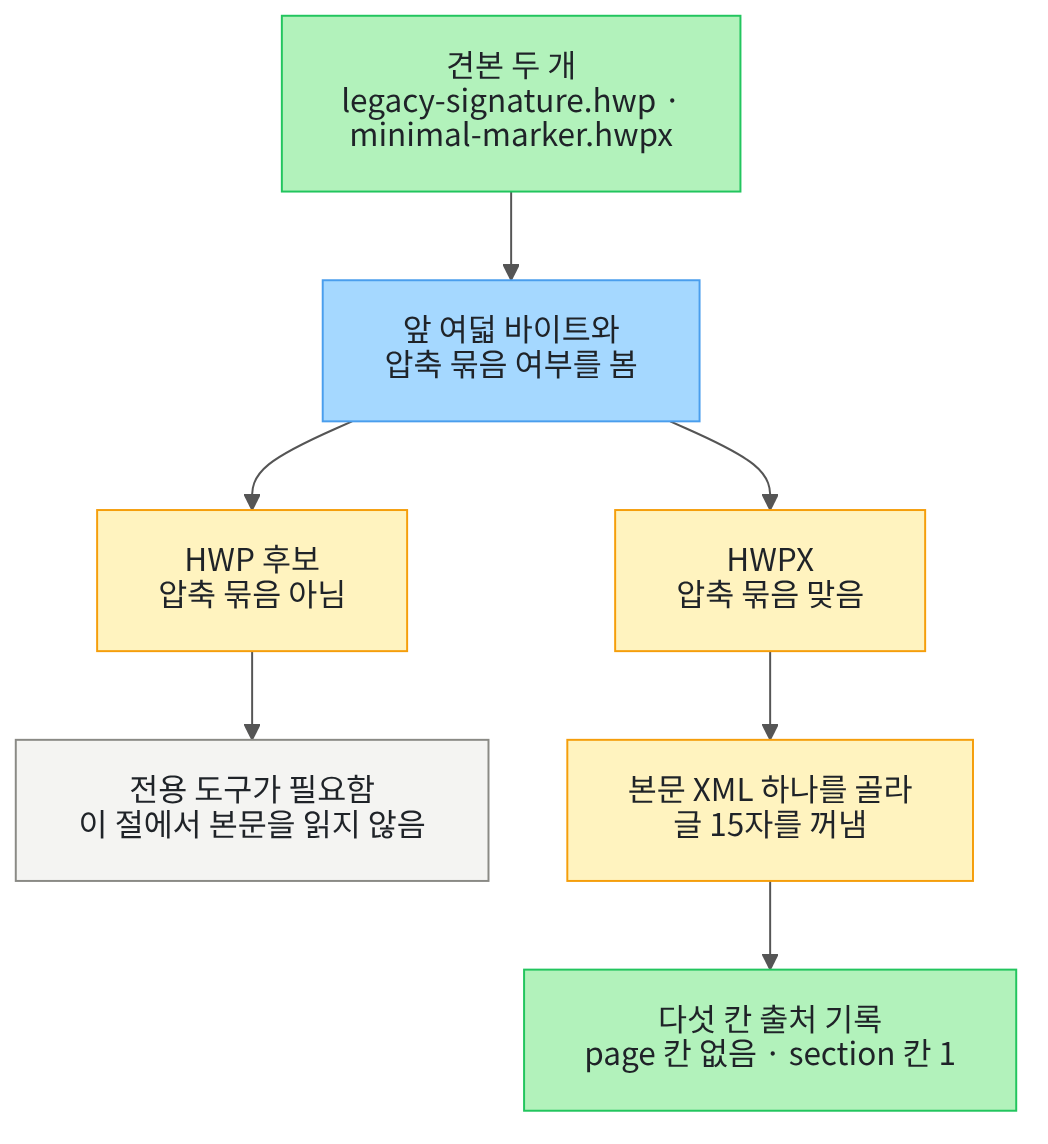

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
이 절에서 따로 설치할 것은 `Document`를 만드는 langchain-core 하나뿐입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain-core==1.6.2"
from importlib.metadata import version

print("langchain-core:", version("langchain-core"))

Note: you may need to restart the kernel to use updated packages.
langchain-core: 1.6.2


**결과 읽기** — 출력 줄은 `langchain-core: 1.6.2` 한 줄입니다.
준비물에 적은 기준 버전과 같습니다.
압축 묶음과 XML을 읽는 도구는 Python에 들어 있어 설치 목록에 없습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
이름 `zipfile`은 압축 묶음을 다루는 도구이고 `ElementTree`는 XML을 읽는 도구입니다.
두 도구의 뜻은 3~7절에서 처음 쓰는 자리에 적었습니다.

In [2]:
# 파일 앞부분 읽기·압축 묶음 열기·XML 읽기·문서 객체 만들기에 쓸 이름을 불러옵니다
import os
import zipfile
from pathlib import Path
from xml.etree import ElementTree

from langchain_core.documents import Document

## 2. 견본 두 개 찾기

01~03절과 같은 방법으로 프로젝트 맨 위 경로를 고릅니다.
후보 세 개를 차례로 확인하고, 있는 경로에서 멈춥니다.
찾는 폴더는 03절과 같은 견본 폴더입니다.

실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [3]:
# 작업 폴더에서 본 프로젝트 맨 위 경로를 후보 세 개 가운데에서 고릅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch10-document-processing/fixtures"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 읽을 견본 두 개의 경로를 만듭니다.
확장자 `.hwp`와 `.hwpx`는 한 글자만 다릅니다.
그런데 파일 안의 모양은 아주 다릅니다. 3절부터 그것을 확인합니다.

In [4]:
# 읽을 견본 두 개의 경로를 만들고 파일이 있는지 확인합니다
fixtures_path = root_path + "/labs/part3/ch10-document-processing/fixtures"
hwp_path = fixtures_path + "/legacy-signature.hwp"
hwpx_path = fixtures_path + "/minimal-marker.hwpx"
print("HWP 견본이 있는가:", os.path.exists(hwp_path))
print("HWPX 견본이 있는가:", os.path.exists(hwpx_path))

HWP 견본이 있는가: True
HWPX 견본이 있는가: True


**결과 읽기** — 출력 두 줄이 모두 `True`입니다.
두 파일은 01절 2절에서 확장자 다섯 가지를 셀 때 이름만 보았던 파일입니다.
나머지 세 개는 03절에서 읽은 `sample.docx`·`sample.html`·`sample.csv`입니다.

## 3. 앞 여덟 바이트 읽기

파일에는 **형식 표시**가 있습니다. 맨 앞 몇 바이트에 형식마다 정해진 값이 적혀 있는 것입니다.
책 표지 뒤에 찍어 둔 도장과 같습니다. 도장을 보면 어느 출판사 책인지 알 수 있습니다.
이 값은 파일 이름과 따로 있어서 확장자를 바꿔도 그대로 남습니다.

이 값을 읽으려면 파일을 **이진 파일**로 열어야 합니다.
글자로 바꾸지 않고 숫자 그대로 읽는 방법입니다. 사진 파일을 열 때와 같습니다.
Ch 2 05절에서 배운 `open()`에 모드 `"rb"`를 주면 그렇게 열립니다.
메서드 `read(8)`은 앞에서 여덟 바이트만 읽고, `hex()`는 그 값을 열여섯 글자로 적습니다.

In [5]:
# 파일을 이진 파일로 열어 앞 여덟 바이트를 읽고 열여섯 글자 값으로 만들어 반환합니다
def read_head_hex(file_path):
    with open(file_path, "rb") as binary_file:
        head_bytes = binary_file.read(8)
    return head_bytes.hex()

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

모드 `"rb"`에서 `r`은 읽기이고 `b`는 이진 파일입니다.
03절에서 CSV를 열 때는 모드를 주지 않아 글자로 읽었습니다.

다음 셀은 견본 두 개의 앞 여덟 바이트를 읽어 견줍니다.

In [6]:
# 견본 두 개의 앞 여덟 바이트를 읽어 값이 같은지 봅니다
hwp_head = read_head_hex(hwp_path)
hwpx_head = read_head_hex(hwpx_path)
print("HWP 견본의 앞 여덟 바이트:", hwp_head)
print("HWPX 견본의 앞 여덟 바이트:", hwpx_head)
print("두 값이 같은가:", hwp_head == hwpx_head)

HWP 견본의 앞 여덟 바이트: d0cf11e0a1b11ae1
HWPX 견본의 앞 여덟 바이트: 504b030414000000
두 값이 같은가: False


**결과 읽기** — 출력 첫 줄은 `HWP 견본의 앞 여덟 바이트: d0cf11e0a1b11ae1`입니다.
둘째 줄은 `HWPX 견본의 앞 여덟 바이트: 504b030414000000`입니다.
마지막 줄 `두 값이 같은가: False`를 보세요. 두 파일의 앞부분이 서로 다릅니다.

앞 네 글자 `504b`는 압축 묶음 파일이 쓰는 값입니다.
HWP 견본의 값은 여러 프로그램이 함께 쓰는 옛 문서 묶음 형식의 값입니다.
그래서 이 값만으로 HWP 파일이라고 단정할 수 없습니다.
이 노트북은 그 갈래를 「HWP 후보」라고 부릅니다.

## 4. 압축 묶음인지 보기

**압축 묶음**은 파일 여러 개를 눌러 담아 한 파일로 만든 것입니다.
서류 여러 장을 지퍼 주머니 하나에 넣어 들고 다니는 것과 같습니다.
겉은 파일 하나인데 안에는 파일 여러 개가 들어 있습니다.

압축 묶음을 다루는 도구 `zipfile`이 Python에 들어 있습니다.
함수 `zipfile.is_zipfile(경로)`는 그 파일이 압축 묶음인지 보고 `True`나 `False`를 냅니다.

In [7]:
# 견본 두 개가 압축 묶음인지 각각 확인합니다
hwp_is_zip = zipfile.is_zipfile(hwp_path)
hwpx_is_zip = zipfile.is_zipfile(hwpx_path)
print("HWP 견본이 압축 묶음인가:", hwp_is_zip)
print("HWPX 견본이 압축 묶음인가:", hwpx_is_zip)

HWP 견본이 압축 묶음인가: False
HWPX 견본이 압축 묶음인가: True


**결과 읽기** — 출력 첫 줄은 `HWP 견본이 압축 묶음인가: False`입니다.
다음 줄 `HWPX 견본이 압축 묶음인가: True`를 보세요.
확장자는 한 글자만 다른데 파일 안의 모양이 다릅니다.

형식 HWPX는 공개된 규격을 따르고 그 안에 XML을 압축 묶음으로 담습니다.
이 견본에는 항목이 두 개이고 본문 XML은 하나입니다.
형식 HWP는 그렇지 않아서 압축 묶음을 다루는 도구로 열 수 없습니다.
그래서 두 형식은 읽는 방법을 나누어야 합니다.

## 5. 압축 묶음 안의 항목 목록

클래스 `zipfile.ZipFile(경로)`는 압축 묶음을 엽니다.
메서드 `namelist()`는 그 안에 든 항목 이름을 목록으로 냅니다.

02절 `pdfplumber.open()`과 03절 `open()`처럼 `with`로 엽니다.
블록이 끝나면 파일이 닫힙니다. 라이브러리 객체에 `with`를 쓰는 세 번째 자리입니다.

In [8]:
# HWPX 견본을 압축 묶음으로 열어 안에 든 항목 이름을 봅니다
with zipfile.ZipFile(hwpx_path) as archive:
    entry_names = archive.namelist()
print("압축 묶음 안의 항목 수:", len(entry_names))
print("항목 이름:", entry_names)

압축 묶음 안의 항목 수: 2
항목 이름: ['Contents/content.hpf', 'Contents/section0.xml']


**결과 읽기** — 출력 줄은 `압축 묶음 안의 항목 수: 2`입니다.
다음 줄 `항목 이름: ['Contents/content.hpf', 'Contents/section0.xml']`이 그 이름입니다.
이름에 `/`가 있어서 압축 묶음 안에도 폴더가 있다는 것을 알 수 있습니다.

항목 두 개는 하는 일이 다릅니다. 이름이 `section0.xml`인 항목이 본문입니다.
항목 `content.hpf`는 묶음에 무엇이 들어 있는지 적어 둔 것입니다.
실제 문서에서는 항목이 더 많을 수 있습니다. 이 견본에는 두 개뿐이고, 다른 문서는 이번에 열지 않았습니다.

## 6. 본문 XML 고르기

항목 이름으로 본문을 고릅니다. 조건은 두 개입니다.
이름이 `Contents/section`으로 시작하고 `.xml`로 끝나는 항목만 고릅니다.

메서드 `startswith()`는 글이 그 글자로 시작하는지 보고 `endswith()`는 끝나는지 봅니다.
조건 하나만 쓰면 본문이 아닌 항목이 함께 들어올 수 있습니다.
실습 폴더 모듈도 같은 조건 두 개를 함께 씁니다.

In [9]:
# 항목 이름이 두 조건을 모두 만족하는 것만 본문 XML 목록에 담습니다
section_names = []
for entry_name in entry_names:
    starts_with_section = entry_name.startswith("Contents/section")
    ends_with_xml = entry_name.endswith(".xml")
    if starts_with_section and ends_with_xml:
        section_names.append(entry_name)
print("본문 XML 수:", len(section_names))
print("본문 XML 이름:", section_names)

본문 XML 수: 1
본문 XML 이름: ['Contents/section0.xml']


**결과 읽기** — 출력 줄은 `본문 XML 수: 1`입니다.
다음 줄 `본문 XML 이름: ['Contents/section0.xml']`이 고른 이름입니다.
항목 `content.hpf`는 `.xml`로 끝나지 않아서 들어오지 않았습니다.

본문이 XML 여러 개에 나뉘어 있는 문서도 있습니다. 그때는 이름의 번호 순서대로 읽어야 합니다.
이 견본에는 본문 XML이 하나뿐이어서 순서를 맞출 일이 없었습니다.

## 7. XML 나무와 요소 이름

본문 XML은 태그로 감싼 글입니다. 03절 HTML과 같은 모양입니다.
다만 태그 이름을 문서 규격이 정해 두었습니다.

압축 묶음에서 항목 하나를 꺼내려면 메서드 `read(이름)`을 씁니다.
이 메서드는 글이 아니라 바이트를 냅니다.
함수 `ElementTree.fromstring(바이트)`에 그 값을 넣으면 요소 나무의 맨 위 요소를 얻습니다.
요소 나무는 태그가 태그를 품은 모양이고 03절에서 본 태그 나무와 같습니다.

In [10]:
# 본문 XML 항목을 바이트로 꺼내 요소 나무의 맨 위 요소를 만듭니다
with zipfile.ZipFile(hwpx_path) as archive:
    xml_bytes = archive.read(section_names[0])
root = ElementTree.fromstring(xml_bytes)
print("꺼낸 바이트 수:", len(xml_bytes))
print("맨 위 요소의 태그 이름:", root.tag)

꺼낸 바이트 수: 204
맨 위 요소의 태그 이름: {http://www.hancom.co.kr/hwpml/2011/paragraph}section


**결과 읽기** — 출력 첫 줄은 `꺼낸 바이트 수: 204`입니다.
다음 줄 `맨 위 요소의 태그 이름: {http://www.hancom.co.kr/hwpml/2011/paragraph}section`을 보세요.
태그 이름 `section` 앞에 중괄호로 감싼 주소가 붙어 있습니다.

이 주소가 **이름 공간**입니다. 어느 규격의 태그인지 알려 주는 표시입니다.
같은 이름의 사람을 회사 이름과 함께 부르는 것과 같습니다.
이름 공간이 붙어 있으면 태그 이름을 그대로 견줄 수 없습니다. 11절에서 그 결과를 확인합니다.

In [11]:
# 태그 이름에서 이름 공간을 떼고 뒤쪽 이름만 남겨 반환합니다
def make_local_name(tag_name):
    return tag_name.split("}")[-1]

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

메서드 `split("}")`는 닫는 중괄호를 기준으로 글을 잘라 목록으로 만듭니다.
그 목록의 마지막 자리 `[-1]`가 이름 공간을 뗀 이름입니다.
이름 공간이 없는 태그는 잘리지 않아 이름이 그대로 남습니다.

다음 셀은 나무 안의 요소를 모두 돌며 이름을 모읍니다.
메서드 `iter()`는 맨 위 요소와 그 안의 요소를 차례로 냅니다.

In [12]:
# 나무 안의 요소를 차례로 돌며 이름 공간을 뗀 이름을 모읍니다
local_names = []
for node in root.iter():
    local_names.append(make_local_name(node.tag))
print("요소 수:", len(local_names))
print("요소 이름:", local_names)

요소 수: 4
요소 이름: ['section', 'p', 'run', 't']


**결과 읽기** — 출력 줄은 `요소 수: 4`입니다.
다음 줄 `요소 이름: ['section', 'p', 'run', 't']`이 나무 안의 이름입니다.
요소 `section`이 맨 위이고 그 안에 `p`가 있습니다. 문단 하나를 뜻합니다.
요소 `p` 안에는 `run`이 있고 그 안에 `t`가 있습니다.

글은 맨 안쪽 `t`에 들어 있습니다. 문서 규격이 그렇게 정해 두었습니다.
03절 HTML에서 제목이 `h1`에 들어 있던 것과 같은 이야기입니다.

## 8. 글이 든 요소만 골라 이어 붙이기

이름이 `t`인 요소만 골라 글을 이어 붙입니다.
요소에 글이 없으면 `node.text`가 `None`입니다. 그때는 건너뜁니다.

고를 이름은 인자로 받습니다. 10절에서 그 값만 바꾸기 때문입니다.

In [13]:
# 나무에서 고른 이름의 요소만 찾아 글을 순서대로 이어 붙여 반환합니다
def read_body_text(xml_root, wanted_name):
    body_text = ""
    for node in xml_root.iter():
        local_name = make_local_name(node.tag)
        if local_name != wanted_name:
            continue
        if node.text is not None:
            body_text = body_text + node.text
    return body_text

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

문장 `continue`는 그 아래를 건너뛰고 다음 요소로 넘어갑니다.
그래서 이름이 다른 요소의 글은 모으지 않습니다.
값 `None`은 글이 아예 없다는 뜻이고 빈 글과 다릅니다.

다음 셀은 이름 `t`를 넣어 본문을 얻습니다.

In [14]:
# 이름이 t인 요소의 글만 모아 본문을 만듭니다
wanted_name = "t"
body_text = read_body_text(root, wanted_name)
print("고른 요소 이름:", wanted_name)
print("본문 글자 수:", len(body_text))
print("본문:")
print(body_text)

고른 요소 이름: t
본문 글자 수: 15
본문:
한글 문서 처리 실습입니다.


**결과 읽기** — 출력 줄은 `본문 글자 수: 15`입니다.
`본문:` 라벨 줄 아래 한 줄을 보세요. 꺼낸 글은 `한글 문서 처리 실습입니다.`입니다.
마침표까지 세어 열다섯 글자입니다.

이 글은 견본 하나에서 얻은 한 문단입니다.
표·각주·그림이 든 실제 문서에서도 같은 방법으로 본문을 얻는지는 실행하지 않았습니다.

## 9. 출처 기록에 자리 칸 더하기

형식 HWPX에도 쪽이 없습니다. 그래서 03절에서 정한 대로 네 칸만 적습니다.
칸은 `doc_id`·`source`·`file_type`·`parser`입니다.

다만 본문이 어느 XML에서 왔는지는 적을 수 있습니다.
03절 CSV의 `row`처럼 **자리 칸**을 하나 더합니다.
이 형식의 자리 칸 이름은 `section`이고 실습 폴더 모듈도 같은 이름을 씁니다.

In [15]:
# 파일 경로와 읽은 방법 이름을 받아 쪽 번호가 없는 네 칸 출처 기록을 만들어 반환합니다(03절 8절과 같은 코드)
def make_unit_record(file_path, parser):
    path_object = Path(file_path)
    suffix = path_object.suffix
    file_type = suffix.replace(".", "").lower()
    record = {"doc_id": path_object.stem, "source": path_object.name,
              "file_type": file_type, "parser": parser}
    return record

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

03절과 같은 코드이고 칸 이름도 같습니다.
`parser` 칸에 적을 이름이 이 절에서 하나 늘어납니다.
압축 묶음을 열어 XML을 읽었으므로 `zip-xml`이라고 적습니다. 실습 폴더 모듈과 같은 글입니다.

다음 셀은 기록을 만들고 자리 칸을 하나 더합니다.

In [16]:
# HWPX 기록을 만들고 자리 칸 section을 하나 더합니다
hwpx_record = make_unit_record(hwpx_path, "zip-xml")
hwpx_record["section"] = 1
print("HWPX 기록:", hwpx_record)
print("기록의 칸 수:", len(hwpx_record))
print("page 칸이 있는가:", "page" in hwpx_record)
print("section 칸의 값:", hwpx_record["section"])

HWPX 기록: {'doc_id': 'minimal-marker', 'source': 'minimal-marker.hwpx', 'file_type': 'hwpx', 'parser': 'zip-xml', 'section': 1}
기록의 칸 수: 5
page 칸이 있는가: False
section 칸의 값: 1


**결과 읽기** — 출력 첫 줄 `HWPX 기록:` 뒤에 `{'doc_id': 'minimal-marker', 'source': 'minimal-marker.hwpx', 'file_type': 'hwpx', 'parser': 'zip-xml', 'section': 1}`이 보입니다.
다음 줄은 `기록의 칸 수: 5`입니다.
셋째 줄 `page 칸이 있는가: False`를 보세요. 쪽 번호 칸은 넣지 않았습니다.

마지막 줄 `section 칸의 값: 1`은 첫 본문 XML에서 왔다는 뜻입니다.
번호를 1부터 센 까닭은 실습 폴더 모듈이 그렇게 세기 때문입니다.
03절 CSV의 `row` 칸은 2부터 셌습니다. 그 파일은 첫 줄이 칸 이름 줄이었기 때문입니다.

In [17]:
# 문서 청크 하나를 받아 파일 형식과 row 칸을 넣은 출처 표시를 만들어 반환합니다(03절 8절과 같은 코드)
def make_unit_mark(chunk):
    doc_id = chunk.metadata["doc_id"]
    file_type = chunk.metadata["file_type"]
    unit_mark = f"[{doc_id} {file_type}]"
    if "row" in chunk.metadata:
        row_number = chunk.metadata["row"]
        unit_mark = f"[{doc_id} {file_type} row.{row_number}]"
    return unit_mark

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

03절과 같은 코드입니다. 이 함수는 기록의 `row` 칸만 봅니다.
그래서 `section` 칸이 있어도 그 값은 표시에 들어가지 않습니다.

자리 칸 이름이 형식마다 달라서 함수를 하나 더 만듭니다.
03절 함수는 고치지 않고 이름을 다르게 둡니다. 05절 이후에도 두 함수를 가려 쓰기 때문입니다.

In [18]:
# 문서 청크 하나를 받아 파일 형식과 section 칸을 넣은 출처 표시를 만들어 반환합니다
def make_section_mark(chunk):
    doc_id = chunk.metadata["doc_id"]
    file_type = chunk.metadata["file_type"]
    section_mark = f"[{doc_id} {file_type}]"
    if "section" in chunk.metadata:
        section_number = chunk.metadata["section"]
        section_mark = f"[{doc_id} {file_type} section.{section_number}]"
    return section_mark

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

함수 `make_unit_mark()`에서 읽는 칸 이름만 `row`에서 `section`으로 바꾼 코드입니다.
자리 칸이 없는 기록에는 파일 형식까지만 붙습니다.

다음 셀은 본문과 기록으로 `Document` 하나를 만들어 두 표시를 견줍니다.

In [19]:
# 본문과 기록으로 Document를 만들고 두 함수가 만든 출처 표시를 견줍니다
hwpx_document = Document(page_content=body_text, metadata=hwpx_record)
unit_mark = make_unit_mark(hwpx_document)
section_mark = make_section_mark(hwpx_document)
print("본문 글자 수:", len(hwpx_document.page_content))
print("메타데이터 칸 수:", len(hwpx_document.metadata))
print("row 칸을 보는 표시:", unit_mark)
print("section 칸을 보는 표시:", section_mark)

본문 글자 수: 15
메타데이터 칸 수: 5
row 칸을 보는 표시: [minimal-marker hwpx]
section 칸을 보는 표시: [minimal-marker hwpx section.1]


**결과 읽기** — 출력 첫 두 줄은 `본문 글자 수: 15`와 `메타데이터 칸 수: 5`입니다.
셋째 줄 `row 칸을 보는 표시: [minimal-marker hwpx]`를 보세요.
기록에 `section` 칸이 있는데도 그 값이 표시에 없습니다.
마지막 줄은 `section 칸을 보는 표시: [minimal-marker hwpx section.1]`입니다.

출처 표시의 모양은 함수가 읽는 칸이 정합니다.
그래서 형식마다 자리 칸 이름을 정해 두고 표시를 만드는 함수와 짝을 맞춥니다.

## 10. 값 하나만 바꿔 보기

바꾸는 값은 고를 요소 이름 하나입니다. `"t"`에서 `"p"`로 바꿉니다.
함수는 고치지 않고 인자만 바꿉니다.

실행 전에 예상합니다. 요소 `p`는 문단을 감싸는 이름이라 글이 바로 들어 있지 않을 것입니다.

In [20]:
# 고를 요소 이름만 p로 바꿔 같은 함수를 다시 부릅니다
changed_name = "p"
changed_text = read_body_text(root, changed_name)
print("바꾼 요소 이름:", changed_name)
print("본문 글자 수:", len(changed_text))
print("빈 글인가:", changed_text == "")

바꾼 요소 이름: p
본문 글자 수: 0
빈 글인가: True


**결과 읽기** — 출력 줄은 `본문 글자 수: 0`입니다. 8절에서는 15자였습니다.
마지막 줄 `빈 글인가: True`를 보세요. 글을 하나도 얻지 못했습니다.

7절 출력 `요소 이름: ['section', 'p', 'run', 't']`을 다시 보세요.
요소 `p`는 나무에 있습니다. 그런데 글은 그 안쪽 `t`에 들어 있습니다.
고를 이름을 잘못 정하면 파일을 열고도 본문이 비어 있습니다.

## 11. 일부러 실패해 보기

이번에는 확장자만 보고 읽는 방법을 정해 봅니다.
이름이 한글 문서 확장자로 끝나니 압축 묶음이겠다고 보는 것입니다.
Before 셀은 HWP 견본을 그대로 압축 묶음으로 엽니다.

오류가 나면 셀이 멈춥니다. 그래서 그 오류 이름만 받아 출력합니다.
Ch 2 05절에서 배운 모양이고 점을 이은 오류 이름은 Ch 4에서 배웠습니다.

In [21]:
# 확장자만 보고 HWP 견본을 압축 묶음으로 열어 봅니다
opened_names = []
error_name = ""
error_message = ""
try:
    with zipfile.ZipFile(hwp_path) as archive:
        opened_names = archive.namelist()
except zipfile.BadZipFile as error:
    error_name = type(error).__name__
    error_message = str(error)
print("읽은 항목 이름 목록:", opened_names)
print("받은 오류 이름:", error_name)
print("받은 오류 글:", error_message)

읽은 항목 이름 목록: []
받은 오류 이름: BadZipFile
받은 오류 글: File is not a zip file


**결과 읽기** — 출력 첫 줄은 `읽은 항목 이름 목록: []`입니다. 항목을 하나도 얻지 못했습니다.
다음 줄 `받은 오류 이름: BadZipFile`이 받은 오류의 이름입니다.
마지막 줄은 `받은 오류 글: File is not a zip file`입니다.

오류가 알려 주는 것은 「압축 묶음이 아니다」까지입니다.
이 파일이 정말 한글 문서인지, 본문이 무엇인지는 알려 주지 않습니다.
확장자 이름만으로 읽는 방법을 정하면 이런 자리에서 멈춥니다.

## 12. 고쳐서 다시 실행하기

3·4절에서 본 값 두 개로 갈래를 먼저 정합니다.
앞 여덟 바이트와 압축 묶음 여부입니다.
갈래마다 할 일을 나누면 HWP 견본에서 멈추지 않습니다.

In [22]:
# 앞 여덟 바이트와 압축 묶음 여부로 파일의 갈래를 정해 반환합니다
ole_marker = "d0cf11e0a1b11ae1"


def recognize_file_kind(file_path):
    head_hex = read_head_hex(file_path)
    if head_hex == ole_marker:
        return "hwp-후보"
    if zipfile.is_zipfile(file_path):
        return "hwpx"
    return "모름"

**결과 읽기** — 이 셀은 이름 하나를 담고 함수를 만들기만 하므로 출력이 없습니다.

값 `d0cf11e0a1b11ae1`은 3절 출력에서 본 HWP 견본의 앞 여덟 바이트입니다.
이름에 담아 두고 식 안에 그대로 쓰지 않습니다.
함수는 이 이름을 함수 밖에서 읽습니다. Ch 5에서 배운 모양입니다.

갈래 이름 `hwp-후보`에 「후보」를 붙인 까닭이 있습니다.
이 값은 여러 프로그램이 함께 쓰는 옛 문서 묶음 형식의 값이기 때문입니다.

다음 셀은 HWPX 파일 하나를 열어 본문을 꺼내는 함수를 만듭니다.
5~8절에서 한 일을 함수 하나에 모은 것입니다.

In [23]:
# HWPX 파일 하나를 열어 본문 XML의 글을 꺼내 반환합니다
def read_hwpx_body(file_path):
    with zipfile.ZipFile(file_path) as archive:
        xml_bytes = archive.read(section_names[0])
    xml_root = ElementTree.fromstring(xml_bytes)
    return read_body_text(xml_root, wanted_name)

**결과 읽기** — 이 셀도 함수를 만들기만 하므로 출력이 없습니다.

이 함수는 6절에서 이 견본에서 고른 이름을 그대로 씁니다.
다른 HWPX 파일이나 본문 XML이 여러 개인 문서를 읽으려면 이름을 고르는 부분까지 함수 안으로 옮겨야 합니다.

다음 셀은 견본 두 개를 차례로 보며 갈래마다 할 일을 나눕니다.

In [24]:
# 갈래를 먼저 정하고 갈래마다 할 일을 나누어 결과를 적습니다
read_report = {}
for file_path in [hwp_path, hwpx_path]:
    file_kind = recognize_file_kind(file_path)
    if file_kind == "hwpx":
        read_report[file_kind] = read_hwpx_body(file_path)
    else:
        read_report[file_kind] = "전용 도구가 필요합니다"
print("갈래별 결과:", read_report)
assert read_report["hwpx"] == body_text

갈래별 결과: {'hwp-후보': '전용 도구가 필요합니다', 'hwpx': '한글 문서 처리 실습입니다.'}


**결과 읽기** — 출력 줄 `갈래별 결과:` 뒤에 `{'hwp-후보': '전용 도구가 필요합니다', 'hwpx': '한글 문서 처리 실습입니다.'}`가 보입니다.
칸 두 개가 갈래 이름이고 값이 갈래마다 한 일입니다.
`assert`도 통과했습니다. 8절에서 얻은 본문과 같은 글입니다.

이번에는 멈추지 않았습니다. 그렇지만 HWP 본문을 읽은 것은 아닙니다.
두 실행 모두 HWP에서 얻은 본문은 없습니다.
After 셀이 바꾼 것은 멈추지 않고 갈래를 적어 둔 것까지입니다.
형식 HWP를 읽으려면 그 형식을 아는 전용 도구가 필요하고 이 절에서는 부르지 않았습니다.

## 13. 정리

1. 확장자는 한 글자 차이인데 앞 여덟 바이트가 달랐습니다. 두 값은 `d0cf11e0a1b11ae1`과 `504b030414000000`입니다.
2. 형식 HWPX는 압축 묶음이어서 항목 두 개가 보였고 그 가운데 본문 XML 하나를 골랐습니다.
3. 글은 맨 안쪽 요소 `t`에 있었습니다. 고를 이름을 `p`로 바꾸자 본문이 0자였습니다.
4. 쪽이 없는 형식이라 네 칸에 자리 칸 `section`을 더해 다섯 칸으로 적었습니다.
5. 확장자만 보고 열면 `BadZipFile` 오류에서 멈췄습니다. 갈래를 먼저 정하면 멈추지 않았습니다.

다음 05절에서는 이렇게 읽은 글을 작은 문서 청크로 나눕니다.
같은 글을 세 가지 방식으로 나누고 나눈 자리와 길이를 견줍니다.
그때도 이 절에서 적은 출처 기록이 문서 청크마다 따라갑니다.